# Part 3: Sociodemographic and residential spatial comparison

This notebook covers the first stage: aggregate comparisons of **age, sex, employment, residential urbanization and home public-transport accessibility, personal car availability and personal bicycle availability**, as background for cycling research. The sample includes all eligible residents, not only cyclists. Activity-chain and activity-location comparisons are subsequent stages; this notebook does not complete all Part 3 requirements.

- Include residents aged 6 and above, including people staying home all day. Source files remain unchanged, including MATSim residents younger than 6.
- Weight Mikrozensus by `WP` and MATSim by one per person. Normalize within each eligible sample; do not multiply MATSim counts by 10.
- Retain unknown categories in the denominator except employment: binary shares use known employment status only; report exclusions separately.
- **Preliminary descriptive results:** the MATSim weekday and source CRS require confirmation; urbanization uses a provisional crosswalk. Composition differences are not cycling-behavior differences or evidence of causality.


In [1]:
from pathlib import Path
import os, tempfile, json, hashlib, zipfile
import xml.etree.ElementTree as ET
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'abmt_part3_mpl'))
os.environ.setdefault('XDG_CACHE_HOME', str(Path(tempfile.gettempdir()) / 'abmt_part3_cache'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'microcensus_filter/microcensus_ne_weekday_persons.csv').exists()), None)
if ROOT is None: raise FileNotFoundError('Run from the project directory or a subdirectory.')
OUT = ROOT / 'part3_results'
OUT.mkdir(exist_ok=True)
MC_PATH = ROOT / 'microcensus_filter/microcensus_ne_weekday_persons.csv'
SIM_PATH = ROOT / 'simulation_filter/simulation_persons.csv'
META_PATH = ROOT / 'simulation_filter/preprocessing_metadata.json'
DICTIONARY = next((ROOT / 'microcensus').glob('*.xlsx'))
mc_raw = pd.read_csv(MC_PATH, dtype=str, keep_default_na=False)
sim_raw = pd.read_csv(SIM_PATH, dtype=str, keep_default_na=False)
metadata = json.loads(META_PATH.read_text())
assert mc_raw.HHNR.is_unique and sim_raw.person.is_unique
assert pd.to_numeric(mc_raw.tag).isin([1, 2, 3, 4, 5]).all()

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120, 'savefig.dpi': 180})
print('Filtered Mikrozensus persons:', len(mc_raw), '| MATSim:', len(sim_raw))
print('MATSim weekday confirmed:', metadata.get('weekday_filter_verified'), '| CRS confirmed:', metadata.get('crs_confirmed'))

Filtered Mikrozensus persons: 2002 | MATSim: 17780
MATSim weekday confirmed: False | CRS confirmed: False


## 1. Verify codes against the local survey dictionary
Read the original Excel codebook without modifying it.

- Sex: `SEX`, used by person field `gesl`.
- Raw descriptive status: `ERWERB`; 1 = full-time, 2 = part-time, 9 = employed with unspecified hours; 3 = in education, 4 = not employed; negative special codes = unknown.
- Spatial context: `STADCHAR`, used by household field `W_staedt_char_2012`, and `W_OEV_KLASSE`.

Original German codebook descriptions are retained as source evidence; analysis labels and explanations are in English.

Employment comparison uses `AMSTAT` (1 employed, 2 unemployed, 3 inactive), with `ESTATUS` as fallback. Under-15 non-employment is an explicit analysis assumption.


In [2]:
def read_dictionary_sheet(path, sheet_name):
    ns = {'s': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(path) as z:
        strings = []
        if 'xl/sharedStrings.xml' in z.namelist():
            sr = ET.fromstring(z.read('xl/sharedStrings.xml'))
            strings = [''.join(e.itertext()) for e in sr.findall('s:si', ns)]
        wb = ET.fromstring(z.read('xl/workbook.xml'))
        sheet = next(e for e in wb.findall('s:sheets/s:sheet', ns) if e.get('name') == sheet_name)
        rid = sheet.get('{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id')
        rels = ET.fromstring(z.read('xl/_rels/workbook.xml.rels'))
        target = next(e.get('Target') for e in rels if e.get('Id') == rid)
        target = target.lstrip('/') if target.startswith('/') else 'xl/' + target
        root = ET.fromstring(z.read(target))
        rows = []
        for r in root.findall('s:sheetData/s:row', ns):
            values = []
            for c in r.findall('s:c', ns):
                v = c.find('s:v', ns)
                value = v.text if v is not None else ''
                if c.get('t') == 's': value = strings[int(value)]
                elif c.get('t') == 'inlineStr': value = ''.join(c.find('s:is', ns).itertext())
                if value: values.append(value)
            rows.append(values)
        return rows

specs = [('Zielpersonen', 'F42100A', {'-99','-98','-97','1','2','3'}), ('Zielpersonen', 'F42100E', {'-99','-98','-97','1','2','3'}), ('Zielpersonen', 'FAMSTAT', {'-99','-98','-97','1','2','3'}), ('Zielpersonen', 'FESTATUS', {'1','2','3','4','5','6','7','8','9','10'}), ('Zielpersonen', 'SEX', {'1','2'}), ('Zielpersonen', 'ERWERB', {'1','2','3','4','9'}),
         ('Haushalte', 'STADCHAR', {'0','1','2','3','4','5','6'}), ('Haushalte', 'W_OEV_KLASSE', {'1','2','3','4','5'})]
evidence = []
for sheet, label, wanted in specs:
    rows = read_dictionary_sheet(DICTIONARY, sheet)
    start = next(i for i,r in enumerate(rows) if r and r[0] == label and len(r) == 3)
    found = set()
    for j, row in enumerate(rows[start:start+15]):
        values = row[1:] if j == 0 else row
        if len(values) >= 2 and values[0] in wanted:
            evidence.append({'sheet': sheet, 'codebook': label, 'code': values[0], 'meaning': values[1]})
            found.add(values[0])
        if found == wanted: break
    assert found == wanted, (label, found)
dictionary_evidence = pd.DataFrame(evidence)
dictionary_evidence.to_csv(OUT / 'dictionary_evidence.csv', index=False)
display(dictionary_evidence)

,sheet,codebook,code,meaning
0,Zielpersonen,F42100A,-99,F41900/01 ungleich 1
1,Zielpersonen,F42100A,-98,keine Antwort
2,Zielpersonen,F42100A,-97,weiss nicht
3,Zielpersonen,F42100A,1,Immer verfügbar
4,Zielpersonen,F42100A,2,Nach Absprache verfügbar
5,Zielpersonen,F42100A,3,Nicht verfügbar
6,Zielpersonen,F42100E,-99,Alter < 18 Jahre ODER kein Auto-Führerschein (...
7,Zielpersonen,F42100E,-98,keine Antwort
8,Zielpersonen,F42100E,-97,weiss nicht
9,Zielpersonen,F42100E,1,Immer verfügbar


## 2. Align samples, weights and denominators
Apply age >= 6 to analysis copies; preserve all source records. Employment shares exclude unresolved employment only, with counts and WP reported separately. Other characteristics retain unknowns in their denominators.


In [3]:
def prepare(raw, age_column, id_column, weight_column=None):
    age = pd.to_numeric(raw[age_column], errors='coerce')
    assert age.dropna().between(0, 120).all()
    df = raw.loc[age.ge(6)].copy()
    df['comparison_age'] = age.loc[df.index]
    df['comparison_weight'] = pd.to_numeric(df[weight_column], errors='coerce') if weight_column else 1.0
    assert df.comparison_weight.notna().all() and np.isfinite(df.comparison_weight).all() and df.comparison_weight.gt(0).all()
    return df
mc = prepare(mc_raw, 'alter', 'HHNR', 'WP')
sim = prepare(sim_raw, 'age', 'person')
sample_audit = pd.DataFrame([
    {'source': name, 'filtered_persons': len(raw), 'missing_age': int(pd.to_numeric(raw[col], errors='coerce').isna().sum()),
     'under_6_retained_in_source': int(pd.to_numeric(raw[col], errors='coerce').lt(6).sum()),
     'analysis_persons': len(df), 'analysis_weight_sum': df.comparison_weight.sum(),
     'at_home_persons_retained': int(df.at_home_all_day.str.lower().eq('true').sum())}
    for name,raw,df,col in [('Mikrozensus',mc_raw,mc,'alter'),('MATSim',sim_raw,sim,'age')]
])
display(sample_audit)
sample_audit.to_csv(OUT / 'sample_audit.csv', index=False)

,source,filtered_persons,missing_age,under_6_retained_in_source,analysis_persons,analysis_weight_sum,at_home_persons_retained
0,Mikrozensus,2002,0,0,2002,870.698861,170
1,MATSim,17780,0,808,16972,16972.000000,1651


## 3. Harmonize the seven characteristics

| Characteristic | Mikrozensus | MATSim | Comparison categories |
|---|---|---|---|
| Age | `alter` | `age` | 6–17, 18–29, 30–44, 45–64, 65+ |
| Sex | `gesl`: 1/2 | `sex`: m/f | Male, Female, Unknown |
| Employment | `AMSTAT`, with `ESTATUS` fallback | `employed`: true/false | Employed, Not employed; unresolved records audited separately |
| Car availability | `f42100e` | `carAvail` | Source categories retained |
| Bicycle availability | `f42100a` | `bikeAvail` | Source categories retained |
| Urbanization | `hh_W_staedt_char_2012` | `municipalityType` | Urban, Suburban, Rural, Unknown |
| Public transport | `hh_W_OeV_KLASSE`: 1–5 | `ovgk`: A/B/C/D/None | A, B, C, D, No class, Unknown |

**Provisional urbanization crosswalk:** the [eqasim Switzerland implementation](https://github.com/eqasim-org/eqasim-switzerland/blob/develop/data/spatial/municipality_types.py) maps survey codes 1/2/3 to Urban, 4/5 to Suburban, and 0/6 to Rural. Mapping code 6 follows that implementation, not the literal statistical definition; this sample contains no code 6. MATSim `urbancore` and `urban` are combined. The scenario-generation version is unknown, so this is a preliminary diagnostic rather than a verified historical crosswalk. Original categories are also displayed for review.

The literal `ovgk` value `None` means no accessibility class, not missing data. Unmatched values such as `crossborder` are Unknown. Spatial reference years may differ; discrepancies do not by themselves establish population-generation errors.

Employment uses AMSTAT first (1 employed; 2/3 not employed). For ages 15+, unresolved records use ESTATUS (1–4 employed; 5–10 not employed), then explicit ERWERB 1/2/9 or 4; ERWERB 3 alone does not establish employment. Ages 6–14 are assumed not employed in the survey; MATSim retains its actual attribute. Missing adult status remains unknown. Education activities never determine employment. MATSim's historical attribute-generation definition remains unverified. A separate age-15+ sensitivity comparison checks the effect of including children.

**Personal vehicle availability (not ownership):** Survey 1 = Always available, 2 = Available by arrangement, 3 = Not available; -99 = Not applicable (routing), -97/-98 or other missing values = Unknown. Car routing excludes respondents under 18 or without a car driving licence / learner permit; bicycle routing refers to F41900/01 eligibility. MATSim always/never map to Always available/Not available. Do not convert survey routing to non-availability or merge arrangement with always/never without verified generation rules. All age-6+ residents remain in each denominator. Survey-only categories are marked unavailable (not zero) in MATSim. These charts show source distributions in separate panels; no availability percentage-point differences are claimed because routing and category definitions differ.


In [4]:
AVAILABILITY_FEATURES = ['car_availability','bike_availability']
AVAILABILITY_CATEGORIES = ['Always available','Available by arrangement','Not available','Not applicable (routing)','Unknown']
FEATURES = {
    'car_availability': ('Personal car availability', AVAILABILITY_CATEGORIES),
    'bike_availability': ('Personal bicycle availability', AVAILABILITY_CATEGORIES),
    'age_group': ('Age group', ['6–17','18–29','30–44','45–64','65+']),
    'sex_group': ('Sex', ['Male','Female','Unknown']),
    'employment_group': ('Employment status', ['Employed','Not employed']),
    'urban_group': ('Urbanization (provisional crosswalk)', ['Urban','Suburban','Rural','Unknown']),
    'pt_group': ('Home public-transport accessibility', ['A Very good','B Good','C Moderate','D Low','No class','Unknown'])
}
FEATURES = {key: FEATURES[key] for key in ['age_group','sex_group','employment_group','urban_group','pt_group','car_availability','bike_availability']}
for df in [mc,sim]:
    df['age_group'] = pd.cut(df.comparison_age, [6,18,30,45,65,float('inf')], labels=FEATURES['age_group'][1], right=False).astype(str)
mc['sex_group'] = mc.gesl.map({'1':'Male','2':'Female'}).fillna('Unknown')
sim['sex_group'] = sim.sex.map({'m':'Male','f':'Female'}).fillna('Unknown')
mc['employment_group'] = mc.AMSTAT.map({'1':'Employed','2':'Not employed','3':'Not employed'}).fillna('Unknown')
mc['employment_rule'] = np.where(mc.employment_group.ne('Unknown'), 'AMSTAT', 'Unresolved')
young = mc.comparison_age.lt(15)
mc.loc[young, 'employment_group'] = 'Not employed'
mc.loc[young, 'employment_rule'] = 'Age 6-14 assumption'
for field, mapping in [('ESTATUS', {str(k): 'Employed' if k <= 4 else 'Not employed' for k in range(1,11)}),
                       ('ERWERB', {'1':'Employed','2':'Employed','9':'Employed','4':'Not employed'})]:
    fallback = mc[field].map(mapping)
    use = ~young & mc.employment_group.eq('Unknown') & fallback.notna()
    mc.loc[use, 'employment_group'] = fallback[use]
    mc.loc[use, 'employment_rule'] = field + ' fallback'
sim['employment_group'] = sim.employed.str.lower().map({'true':'Employed','false':'Not employed'}).fillna('Unknown')
sim['employment_rule'] = np.where(sim.employment_group.ne('Unknown'), 'employed attribute', 'Unresolved')
audit_rows = []
for source, df in [('Mikrozensus',mc),('MATSim',sim)]:
    audit = df.groupby(['employment_rule','employment_group']).agg(sample_n=('comparison_weight','size'), weight_sum=('comparison_weight','sum')).reset_index()
    audit['source'] = source
    audit['eligible_weight_pct'] = 100 * audit.weight_sum / df.comparison_weight.sum()
    audit_rows.append(audit)
employment_audit = pd.concat(audit_rows,ignore_index=True)
employment_audit.to_csv(OUT/'employment_classification_audit.csv',index=False)
mc[['HHNR','comparison_age','WP','AMSTAT','ESTATUS','ERWERB','employment_group','employment_rule']].to_csv(OUT/'employment_person_audit_microcensus.csv',index=False)
display(employment_audit)
print('MATSim employed residents aged 6-14:', int((sim.comparison_age.lt(15) & sim.employment_group.eq('Employed')).sum()))
mc['urban_group'] = mc.hh_W_staedt_char_2012.map({'0':'Rural','1':'Urban','2':'Urban','3':'Urban','4':'Suburban','5':'Suburban','6':'Rural'}).fillna('Unknown')
sim['urban_group'] = sim.municipalityType.map({'urbancore':'Urban','urban':'Urban','suburban':'Suburban','rural':'Rural'}).fillna('Unknown')
mc['pt_group'] = mc.hh_W_OeV_KLASSE.map({'1':'A Very good','2':'B Good','3':'C Moderate','4':'D Low','5':'No class'}).fillna('Unknown')
sim['pt_group'] = sim.ovgk.map({'A':'A Very good','B':'B Good','C':'C Moderate','D':'D Low','None':'No class'}).fillna('Unknown')

for feature, survey_field, sim_field in [('car_availability','f42100e','carAvail'),('bike_availability','f42100a','bikeAvail')]:
    mc[feature] = mc[survey_field].map({'1':'Always available','2':'Available by arrangement','3':'Not available','-99':'Not applicable (routing)'}).fillna('Unknown')
    sim[feature] = sim[sim_field].str.lower().map({'always':'Always available','never':'Not available'}).fillna('Unknown')

raw_fields = [('car_availability','f42100e','carAvail'),('bike_availability','f42100a','bikeAvail'),('sex_group','gesl','sex'),('employment_group','ERWERB','employed'),
              ('urban_group','hh_W_staedt_char_2012','municipalityType'),('pt_group','hh_W_OeV_KLASSE','ovgk')]
raw_audits = []
for feature, mf, sf in raw_fields:
    for source,df,field in [('Mikrozensus',mc,mf),('MATSim',sim,sf)]:
        audit = df.groupby([field,feature], dropna=False).agg(sample_n=('comparison_weight','size'),weight_sum=('comparison_weight','sum')).reset_index()
        audit.columns = ['raw_code','mapped_category','sample_n','weight_sum']
        audit['source'], audit['feature'], audit['source_field'] = source,feature,field
        audit['share_pct'] = 100 * audit.weight_sum / df.comparison_weight.sum()
        raw_audits.append(audit)
raw_audit = pd.concat(raw_audits, ignore_index=True)
raw_audit.to_csv(OUT / 'category_mapping_audit.csv', index=False)
display(raw_audit.loc[raw_audit.feature.isin(['urban_group','employment_group'])])

,employment_rule,employment_group,sample_n,weight_sum,source,eligible_weight_pct
0,AMSTAT,Employed,1047,471.810551,Mikrozensus,54.187570
1,AMSTAT,Not employed,721,309.372332,Mikrozensus,35.531496
2,Age 6-14 assumption,Not employed,231,87.147504,Mikrozensus,10.008914
3,Unresolved,Unknown,3,2.368473,Mikrozensus,0.272020
4,employed attribute,Employed,9038,9038.000000,MATSim,53.252416
5,employed attribute,Not employed,7934,7934.000000,MATSim,46.747584


,raw_code,mapped_category,sample_n,weight_sum,source,feature,source_field,share_pct
20,-98,Unknown,3,2.368473,Mikrozensus,employment_group,ERWERB,0.272020
21,1,Employed,623,292.686632,Mikrozensus,employment_group,ERWERB,33.615139
22,2,Employed,355,151.166010,Mikrozensus,employment_group,ERWERB,17.361457
23,3,Employed,63,25.513311,Mikrozensus,employment_group,ERWERB,2.930211
24,3,Not employed,324,129.037964,Mikrozensus,employment_group,ERWERB,14.820045
25,4,Not employed,628,267.481872,Mikrozensus,employment_group,ERWERB,30.720365
26,9,Employed,6,2.444598,Mikrozensus,employment_group,ERWERB,0.280763
27,false,Not employed,7934,7934.000000,MATSim,employment_group,employed,46.747584
28,true,Employed,9038,9038.000000,MATSim,employment_group,employed,53.252416
29,0,Rural,171,91.606791,Mikrozensus,urban_group,hh_W_staedt_char_2012,10.521065


MATSim employed residents aged 6-14: 0


## 4. Compute shares and percentage-point differences

For each characteristic:

`Survey share = category WP sum / total eligible WP sum`

`MATSim share = category person count / total eligible person count`

`Difference (percentage points) = MATSim share * 100 - survey share * 100`

Positive values indicate a higher MATSim share. These are descriptive diagnostics without significance tests: full complex-survey design information is unavailable, and synthetic agents should not be treated as an independent random survey sample.

Employment is the exception: denominators include only residents with known binary status. Unresolved counts and weighted shares are exported in employment_classification_audit.csv.


In [5]:
results = []
for feature,(title,categories) in FEATURES.items():
    for df in [mc,sim]: assert df[feature].isin(categories + (['Unknown'] if feature == 'employment_group' else [])).all()
    grouped = []
    for source,df in [('mc',mc),('sim',sim)]:
        df = df.loc[df[feature].isin(categories)]
        tab = df.groupby(feature).agg(sample_n=('comparison_weight','size'),weight_sum=('comparison_weight','sum')).reindex(categories, fill_value=0)
        tab['share_pct'] = 100 * tab.weight_sum / df.comparison_weight.sum()
        assert np.isclose(tab.share_pct.sum(),100)
        grouped.append(tab.add_prefix(source+'_'))
    result = pd.concat(grouped,axis=1).reset_index().rename(columns={feature:'category'})
    result['difference_pp'] = result.sim_share_pct - result.mc_share_pct
    assert np.isclose(result.difference_pp.sum(),0)
    result['feature'],result['feature_label'] = feature,title
    results.append(result)
comparison = pd.concat(results,ignore_index=True)
comparison['sim_category_available'] = ~(comparison.feature.isin(AVAILABILITY_FEATURES) & comparison.category.isin(['Available by arrangement','Not applicable (routing)']))
comparison.loc[~comparison.sim_category_available, ['sim_sample_n','sim_weight_sum','sim_share_pct']] = np.nan
comparison.loc[comparison.feature.isin(AVAILABILITY_FEATURES), 'difference_pp'] = np.nan
comparison.to_csv(OUT / 'seven_feature_comparison.csv',index=False)
comparison.loc[~comparison.feature.isin(AVAILABILITY_FEATURES)].to_csv(OUT / 'five_feature_comparison.csv',index=False)
comparison.loc[comparison.feature.isin(AVAILABILITY_FEATURES)].to_csv(OUT / 'vehicle_availability_comparison.csv',index=False)
display(comparison[['feature_label','category','mc_sample_n','sim_sample_n','mc_share_pct','sim_share_pct','difference_pp']].round(2))
sensitivity = []
for minimum_age in [6,15]:
    for source, df in [('Mikrozensus',mc),('MATSim',sim)]:
        eligible = df.loc[df.comparison_age.ge(minimum_age)]
        known = eligible.loc[eligible.employment_group.ne('Unknown')]
        for category in FEATURES['employment_group'][1]:
            part = known.loc[known.employment_group.eq(category)]
            sensitivity.append(dict(source=source,minimum_age=minimum_age,category=category,sample_n=len(part),known_n=len(known),excluded_n=len(eligible)-len(known),share_pct=100*part.comparison_weight.sum()/known.comparison_weight.sum()))
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(OUT/'employment_age_sensitivity.csv',index=False)
display(sensitivity.round(3))


,feature_label,category,mc_sample_n,sim_sample_n,mc_share_pct,sim_share_pct,difference_pp
0,Age group,6–17,309,2160.0,13.22,12.73,-0.49
1,Age group,18–29,276,2682.0,16.57,15.80,-0.76
2,Age group,30–44,382,3417.0,21.43,20.13,-1.30
3,Age group,45–64,602,4951.0,28.30,29.17,0.87
4,Age group,65+,433,3762.0,20.48,22.17,1.68
5,Sex,Male,983,8270.0,49.88,48.73,-1.15
6,Sex,Female,1019,8702.0,50.12,51.27,1.15
7,Sex,Unknown,0,0.0,0.00,0.00,0.00
8,Employment status,Employed,1047,9038.0,54.34,53.25,-1.08
9,Employment status,Not employed,952,7934.0,45.66,46.75,1.08


,source,minimum_age,category,sample_n,known_n,excluded_n,share_pct
0,Mikrozensus,6,Employed,1047,1999,3,54.335
1,Mikrozensus,6,Not employed,952,1999,3,45.665
2,MATSim,6,Employed,9038,16972,0,53.252
3,MATSim,6,Not employed,7934,16972,0,46.748
4,Mikrozensus,15,Employed,1047,1768,3,60.397
5,Mikrozensus,15,Not employed,721,1768,3,39.603
6,MATSim,15,Employed,9038,15371,0,58.799
7,MATSim,15,Not employed,6333,15371,0,41.201


## 5. Visualize distributions and differences
Deep teal (#005F73) represents WP-weighted Mikrozensus shares; ochre orange (#CA6702) represents MATSim person-count shares. Colors follow the user-provided Ocean Sunset palette. Unknown categories remain visible except employment, whose unresolved records are reported separately and excluded from binary shares. The original five characteristics include a percentage-point difference panel. Availability uses separate source panels because survey routing and the intermediate availability category have no verified MATSim equivalent. Raw counts are not used to compare the two sample distributions.


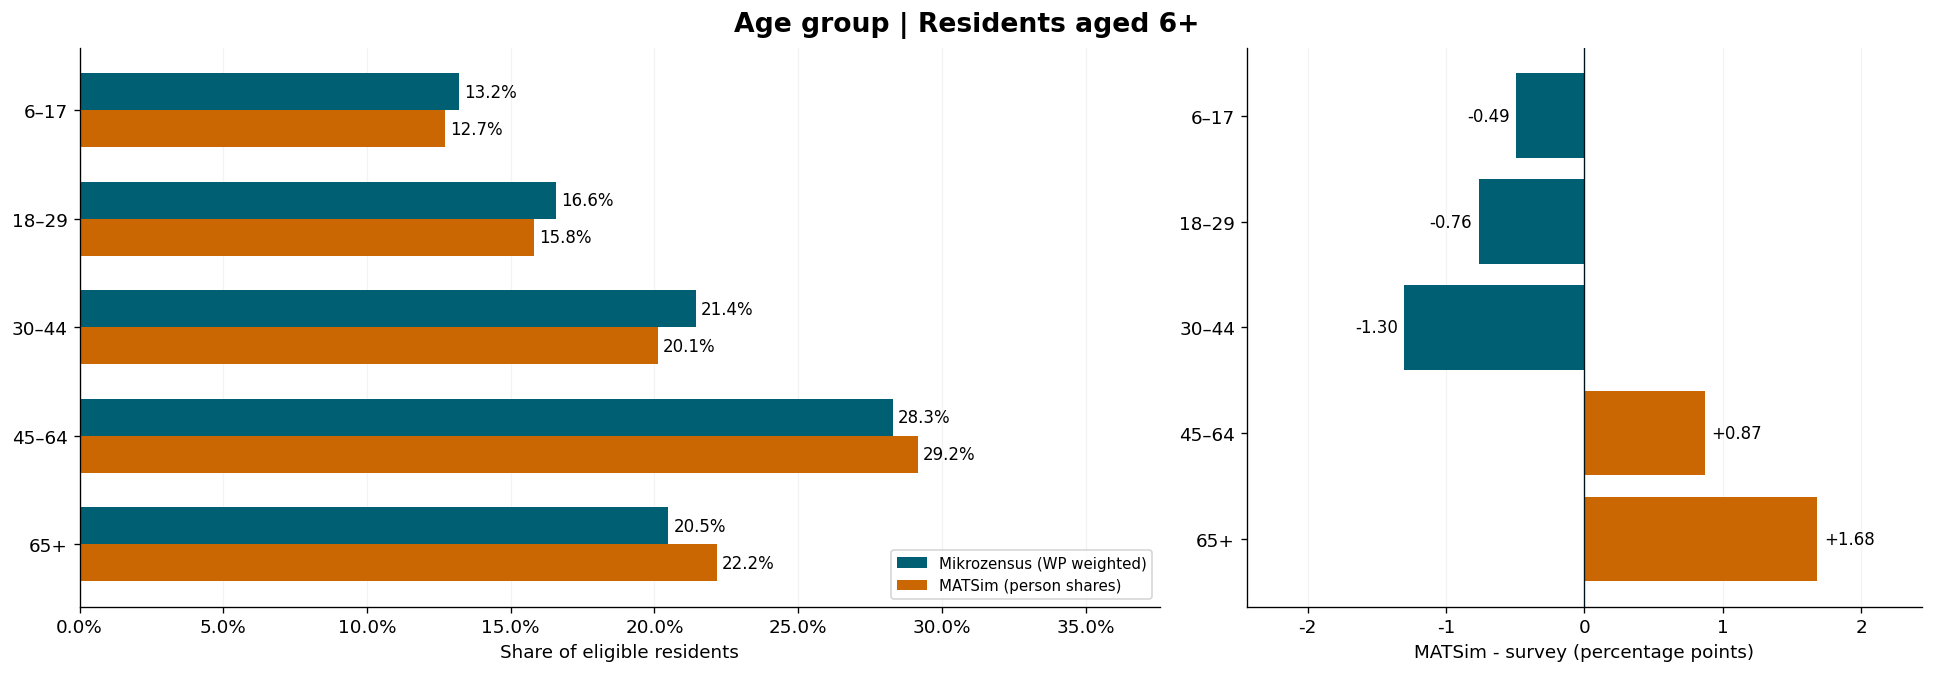

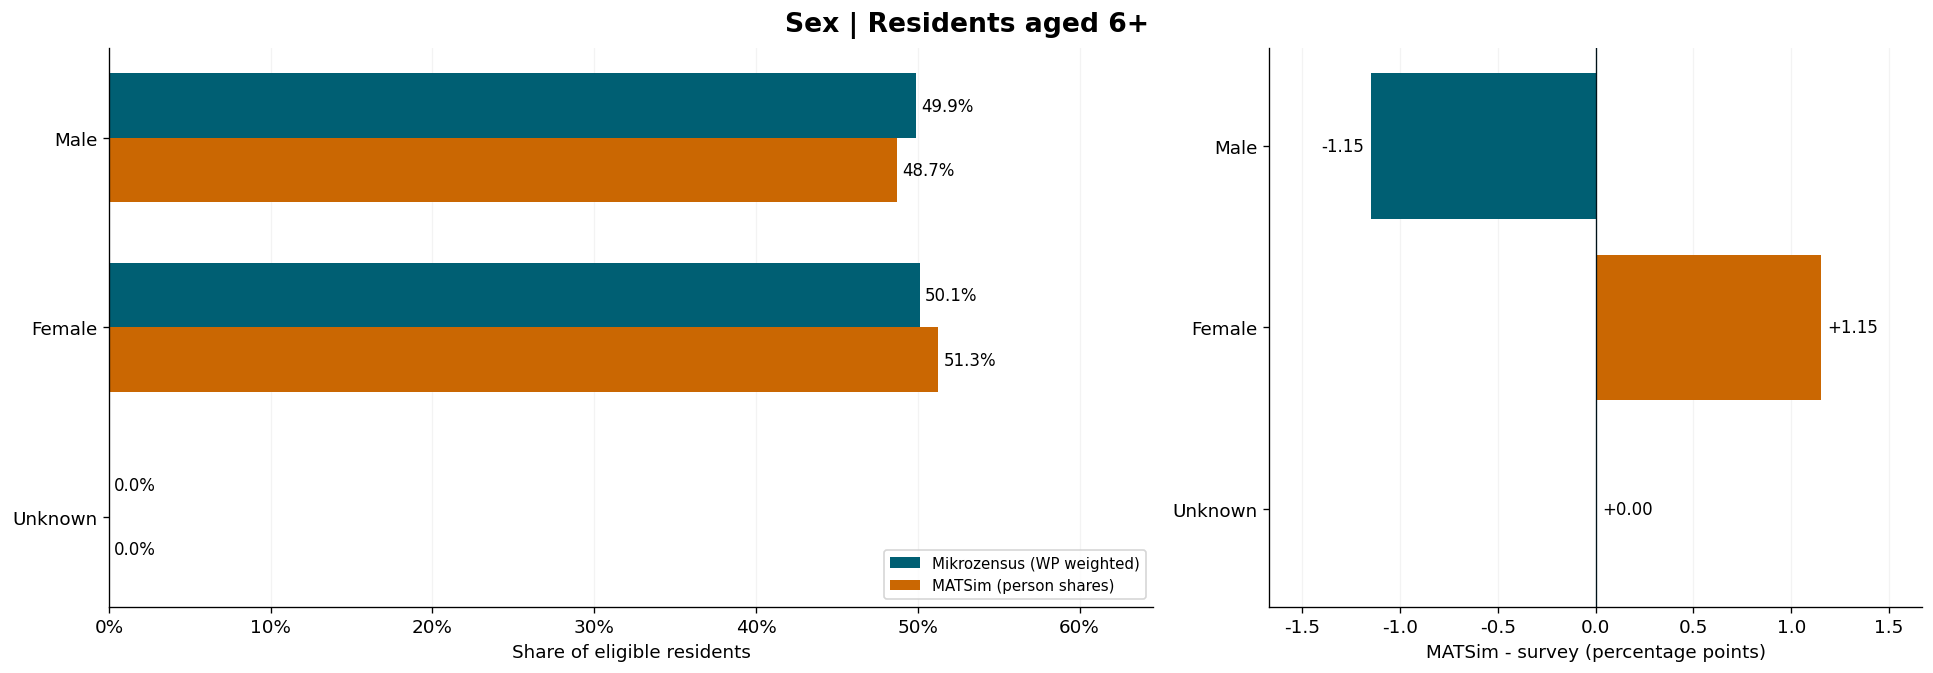

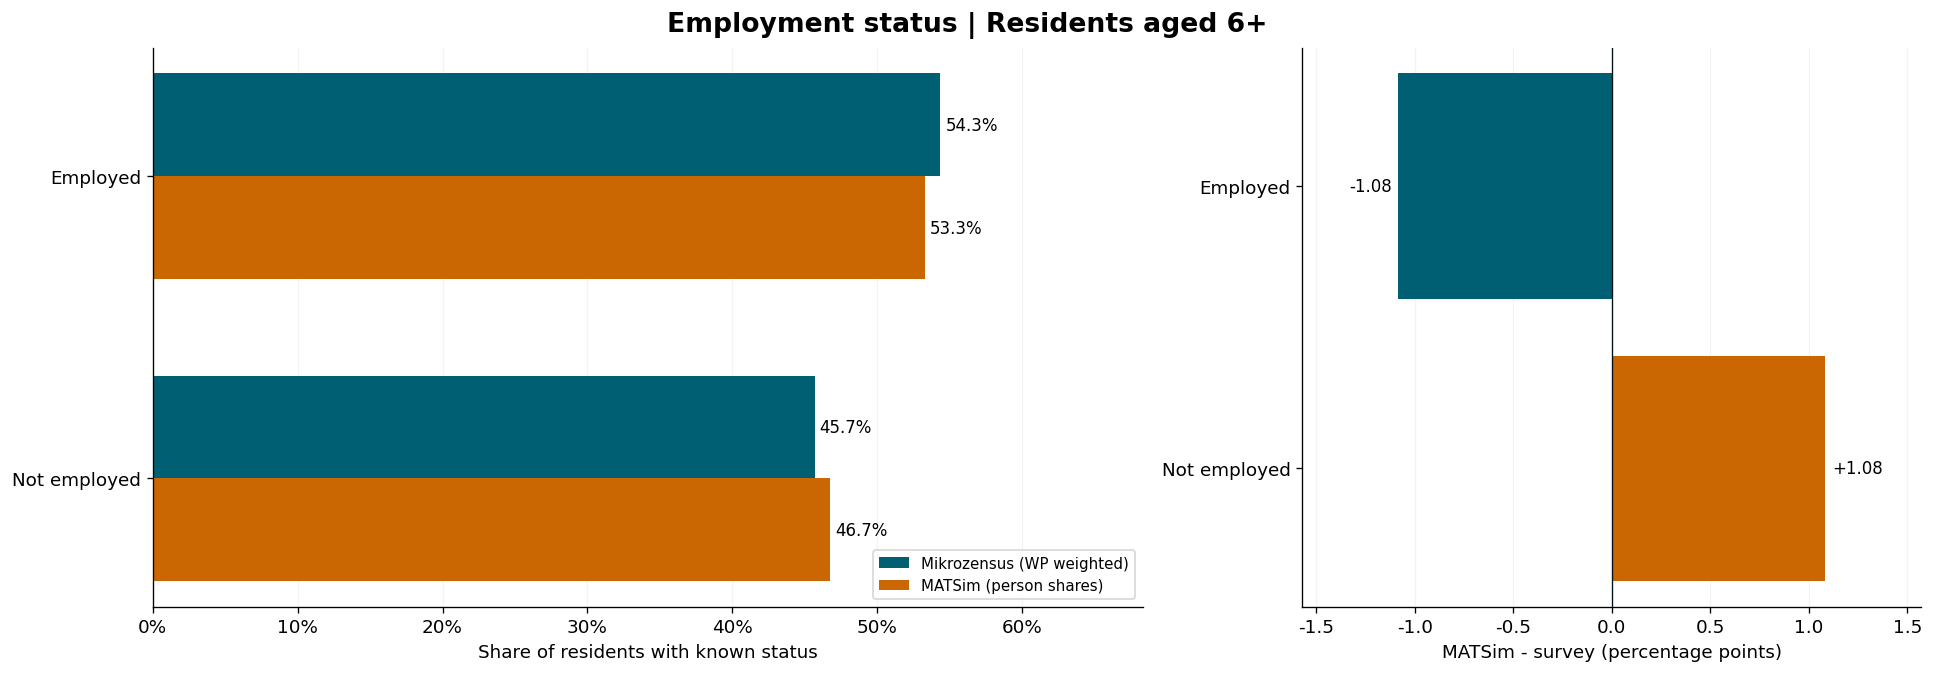

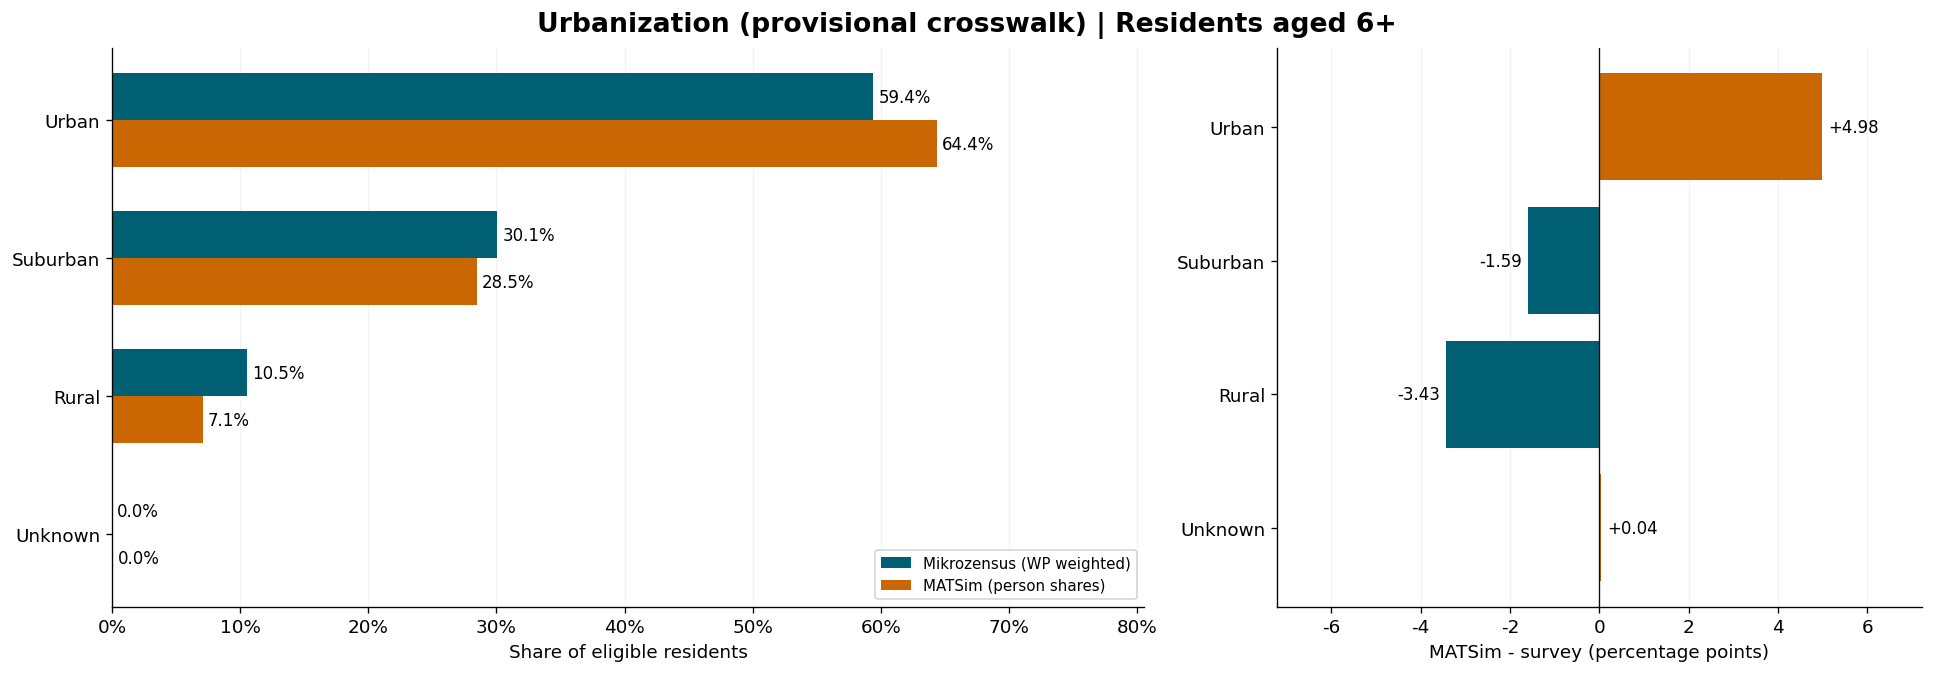

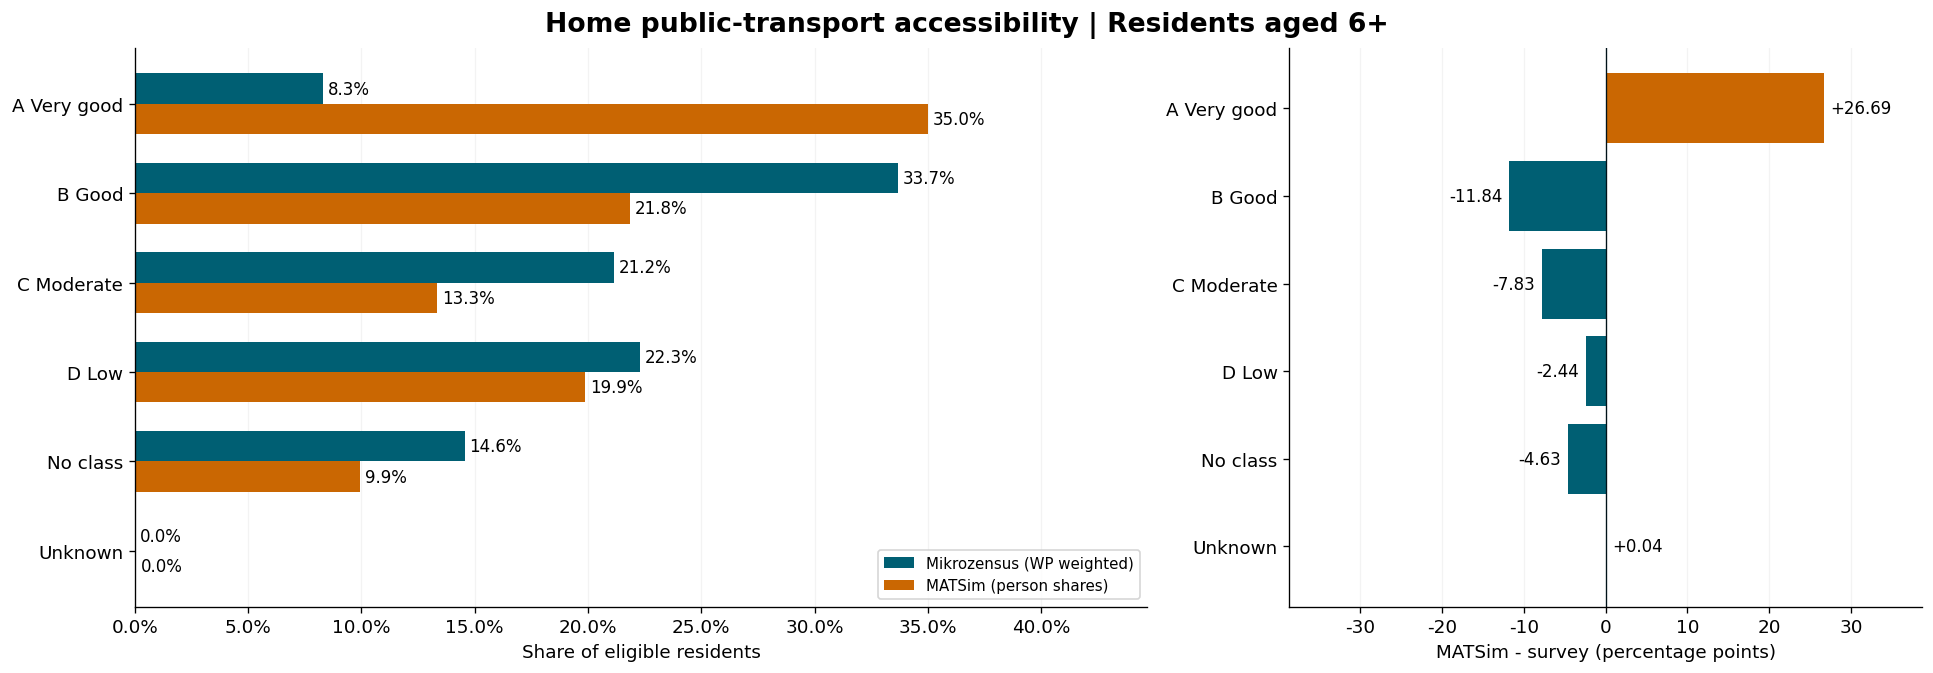

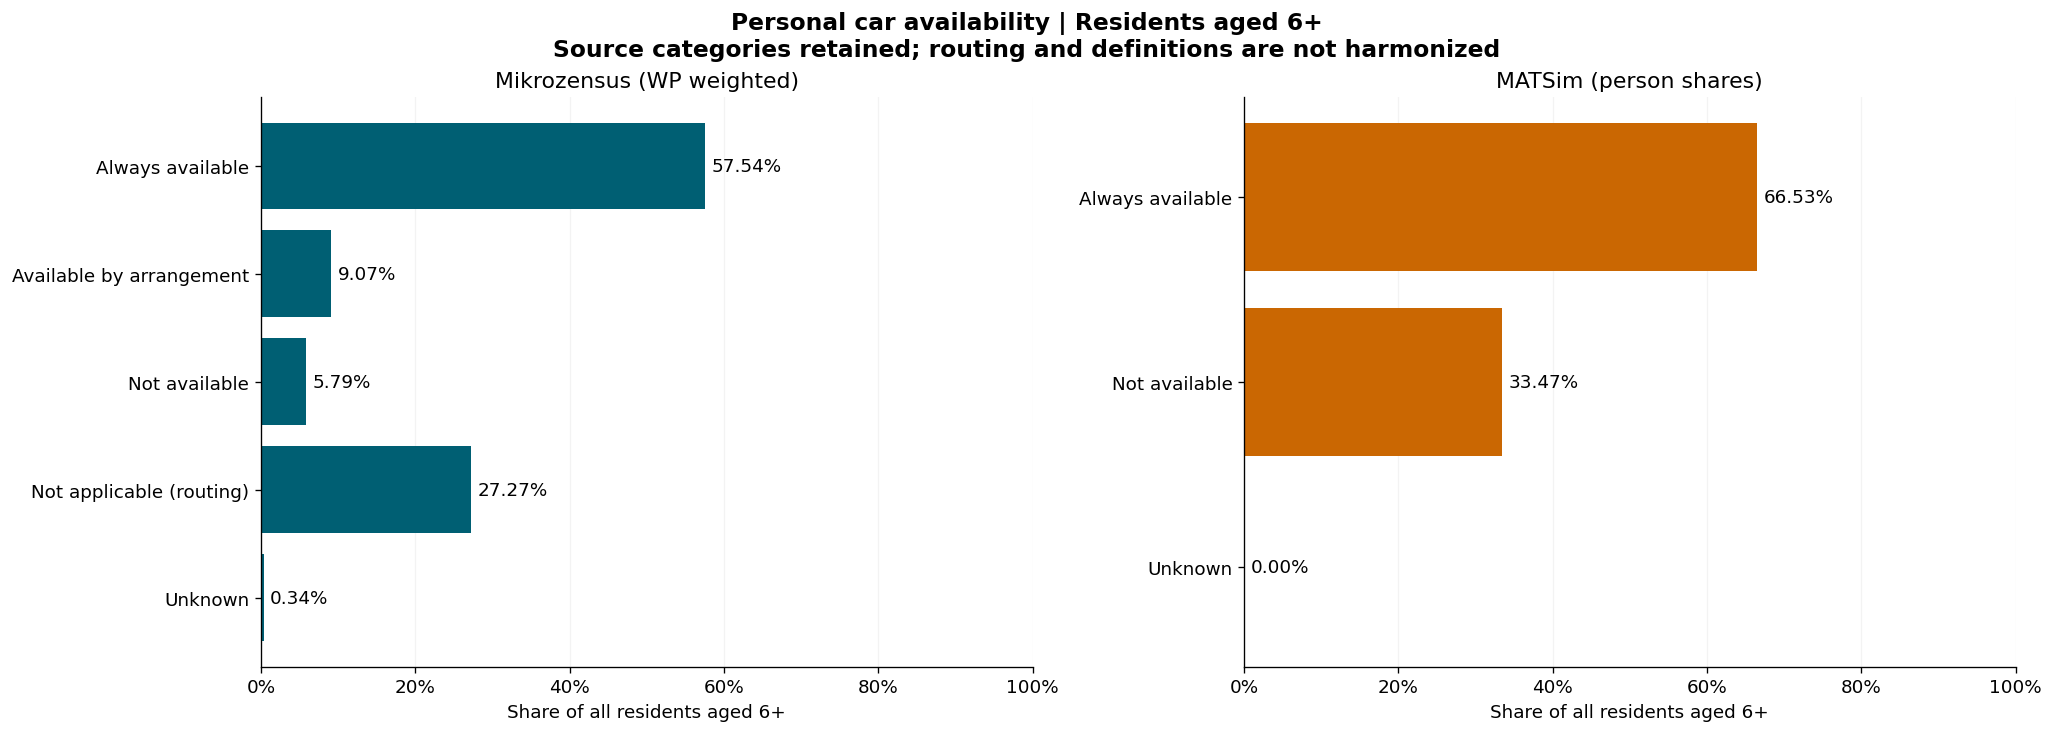

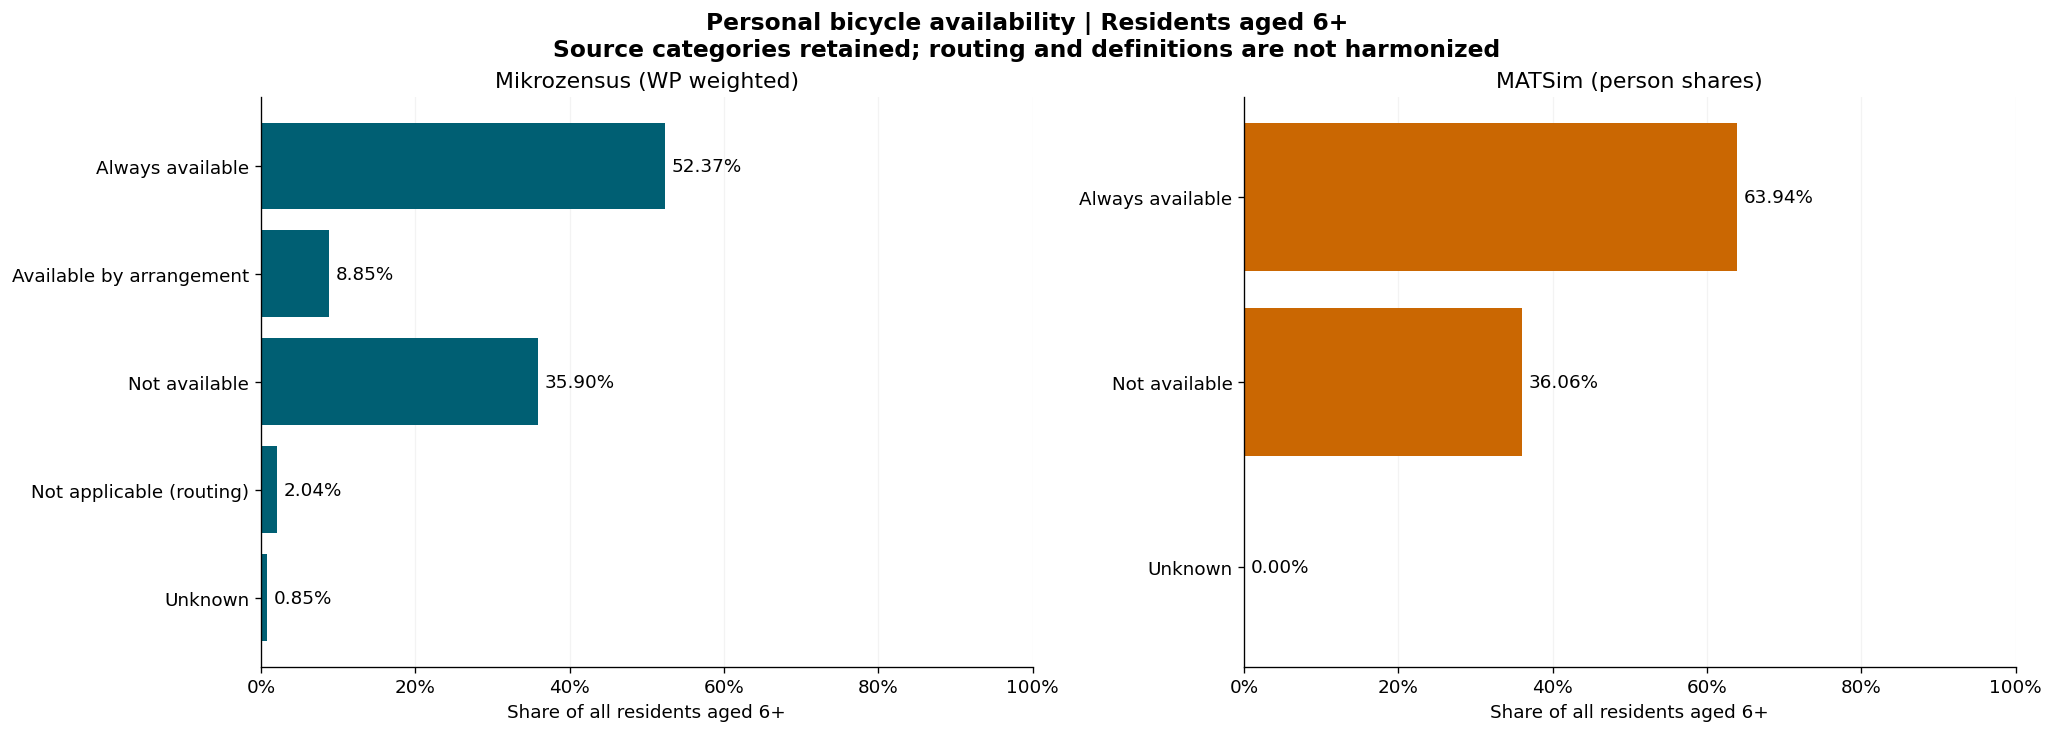

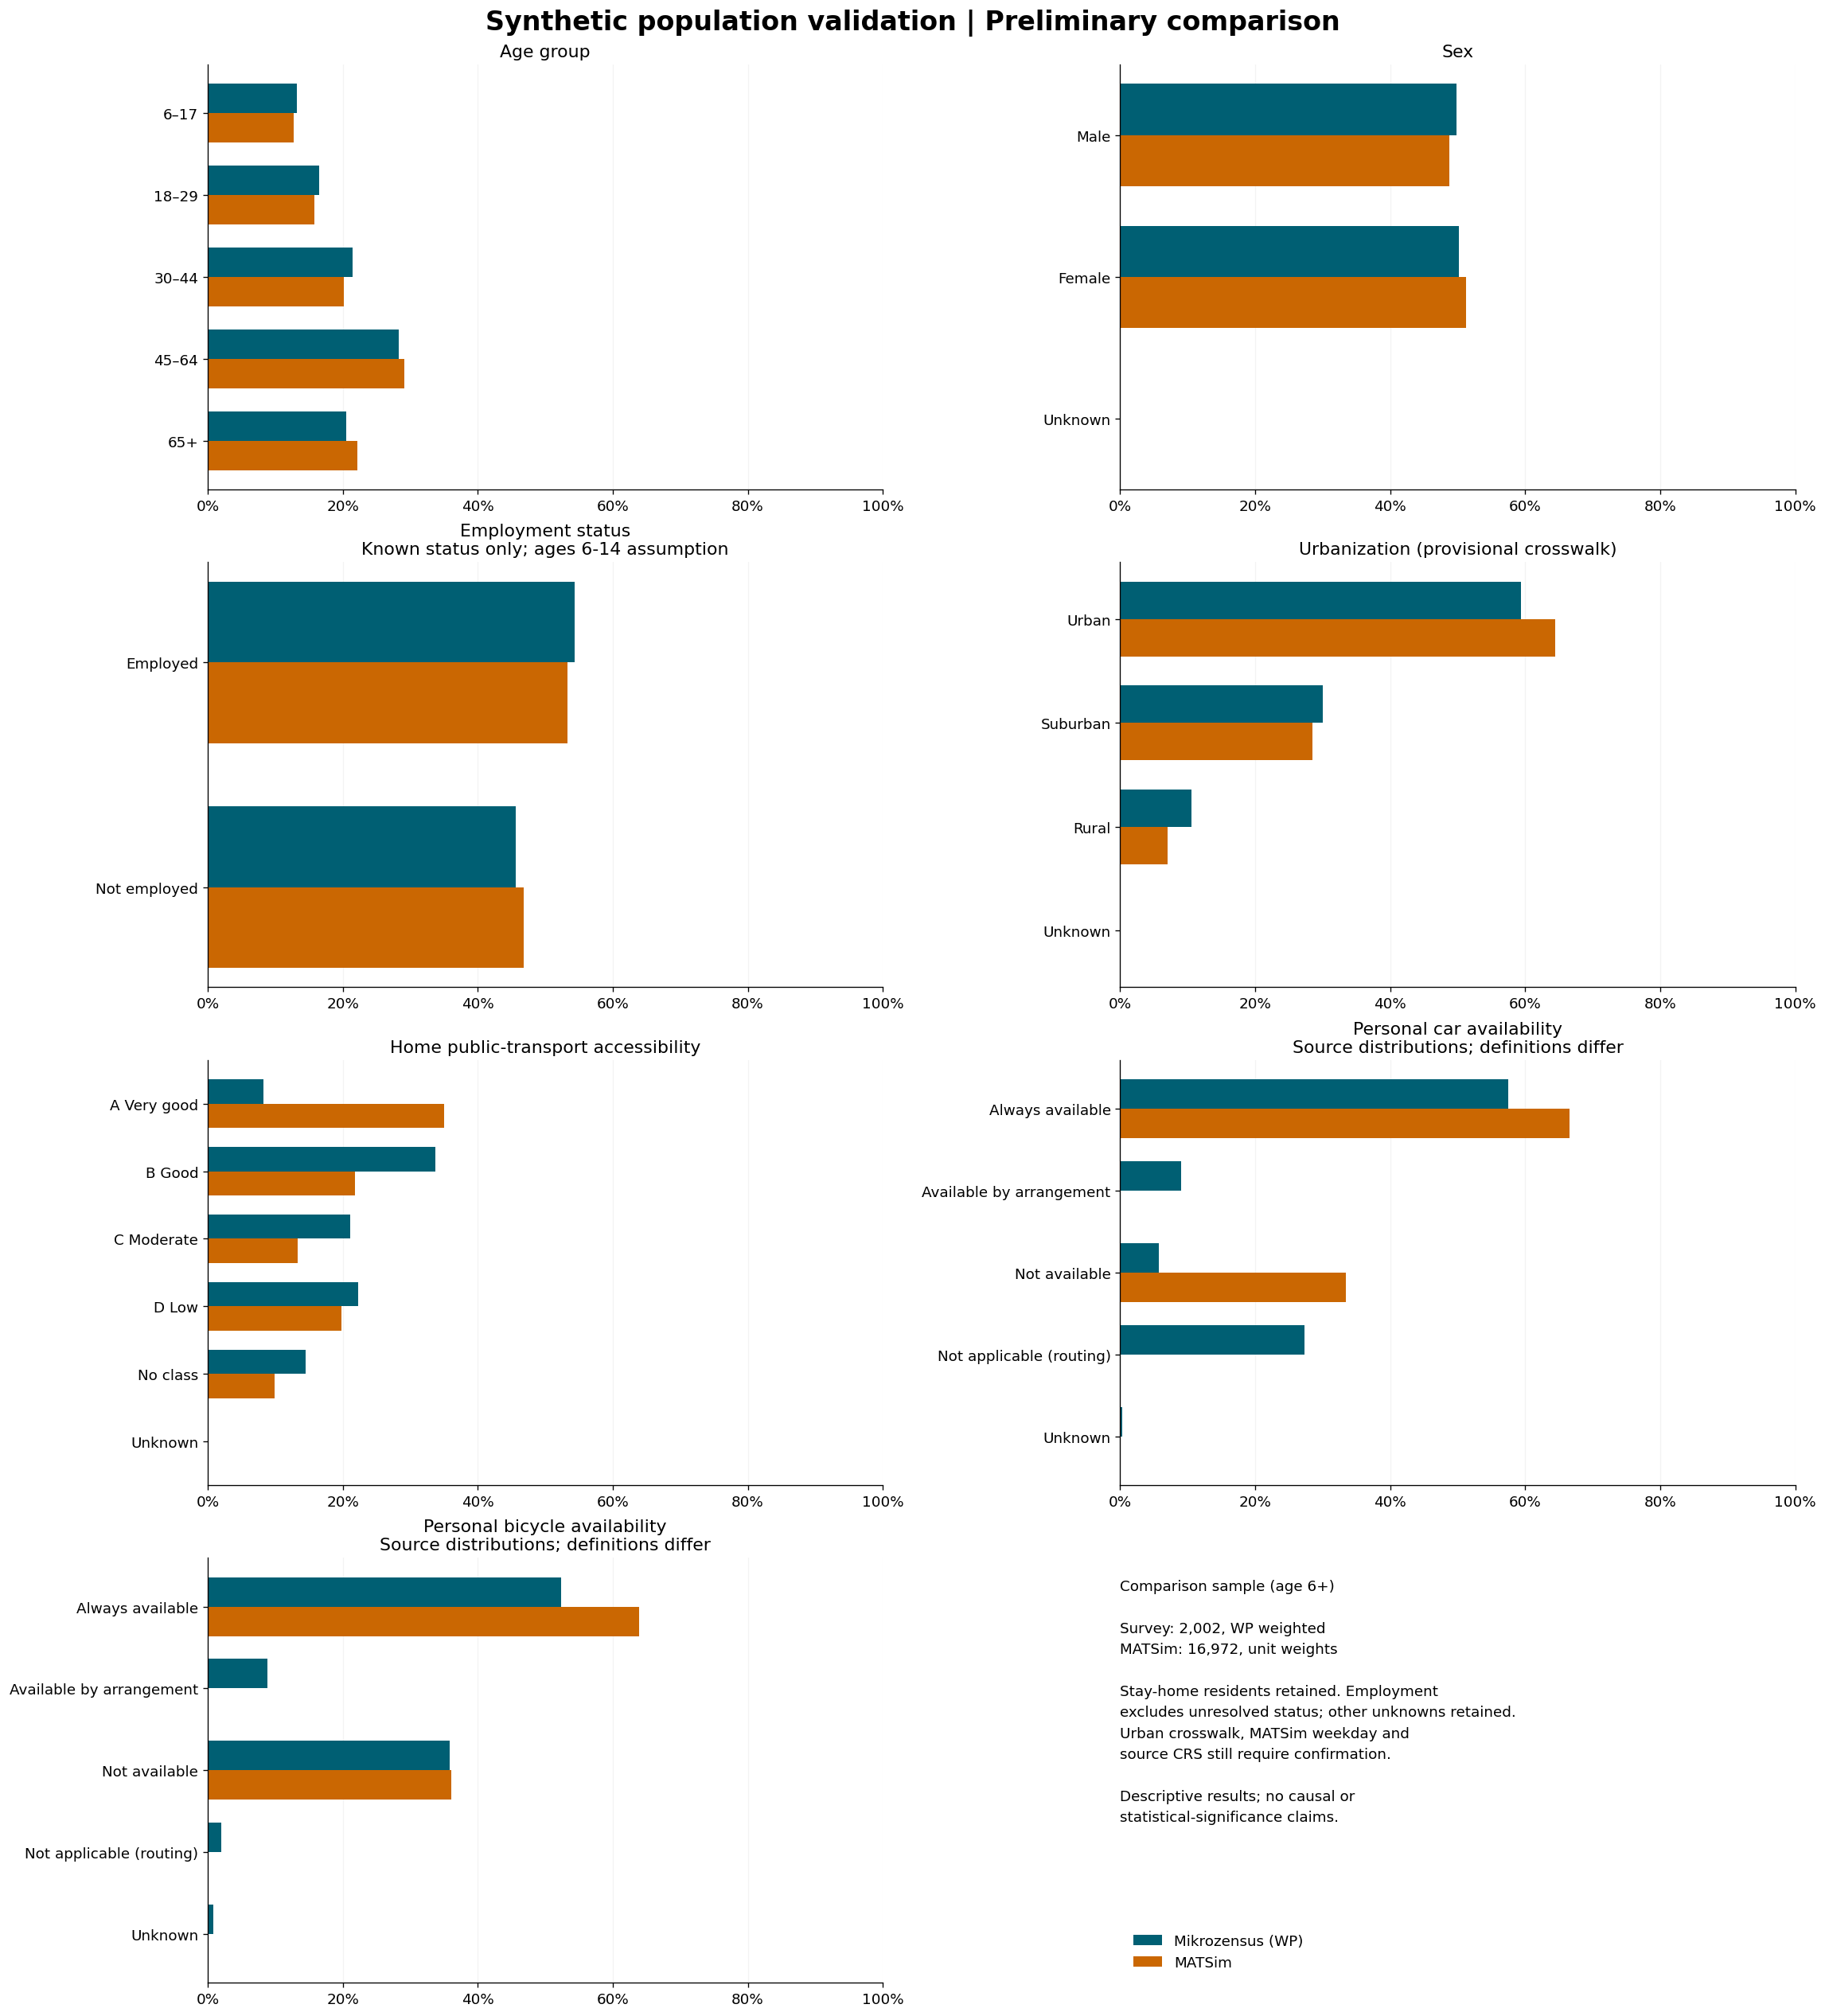

In [6]:
# Ocean Sunset palette supplied by the user.
COLORS = {'mc':'#005F73','sim':'#CA6702','positive':'#CA6702','negative':'#005F73'}
for feature,(title,categories) in FEATURES.items():
    d = comparison.loc[comparison.feature.eq(feature)].reset_index(drop=True)
    if feature in AVAILABILITY_FEATURES:
        fig, axs = plt.subplots(1,2,figsize=(17,6),layout='constrained')
        for ax,prefix,label in [(axs[0],'mc','Mikrozensus (WP weighted)'),(axs[1],'sim','MATSim (person shares)')]:
            part = d if prefix == 'mc' else d.loc[d.sim_category_available]
            bars = ax.barh(part.category,part[prefix+'_share_pct'],color=COLORS[prefix])
            ax.bar_label(bars,fmt='%.2f%%',padding=4)
            ax.invert_yaxis(); ax.set_xlim(0,100); ax.xaxis.set_major_formatter(PercentFormatter(100))
            ax.set_title(label); ax.set_xlabel('Share of all residents aged 6+')
            ax.grid(axis='x',alpha=.15); ax.set_axisbelow(True)
        fig.suptitle(title + ' | Residents aged 6+\nSource categories retained; routing and definitions are not harmonized',fontsize=14,fontweight='bold')
        fig.savefig(OUT/f'{feature}_comparison.png',bbox_inches='tight')
        fig.savefig(OUT/f'{feature}_comparison.pdf',bbox_inches='tight')
        display(fig); plt.close(fig)
        continue
    fig,(left,right) = plt.subplots(1,2,figsize=(16,5.5),gridspec_kw={'width_ratios':[1.6,1]},layout='constrained')
    y=np.arange(len(d));h=0.34
    b1=left.barh(y-h/2,d.mc_share_pct,h,label='Mikrozensus (WP weighted)',color=COLORS['mc'])
    b2=left.barh(y+h/2,d.sim_share_pct,h,label='MATSim (person shares)',color=COLORS['sim'])
    left.bar_label(b1,fmt='%.1f%%',padding=3,fontsize=10);left.bar_label(b2,fmt='%.1f%%',padding=3,fontsize=10)
    left.set(yticks=y,yticklabels=d.category,xlabel='Share of residents with known status' if feature == 'employment_group' else 'Share of eligible residents',xlim=(0,max(d.mc_share_pct.max(),d.sim_share_pct.max())*1.22+2))
    left.xaxis.set_major_formatter(PercentFormatter(100));left.invert_yaxis();left.grid(axis='x',alpha=.15);left.set_axisbelow(True)
    left.legend(loc='lower right',fontsize=9)
    bars=right.barh(y,d.difference_pp,color=[COLORS['positive'] if v>=0 else COLORS['negative'] for v in d.difference_pp])
    right.bar_label(bars,labels=[f'{v:+.2f}' for v in d.difference_pp],padding=4,fontsize=10)
    extent=max(abs(d.difference_pp).max()*1.45,1)
    right.set(yticks=y,yticklabels=d.category,xlim=(-extent,extent),xlabel='MATSim - survey (percentage points)')
    right.invert_yaxis();right.axvline(0,color='#001219',lw=.8);right.grid(axis='x',alpha=.15);right.set_axisbelow(True)
    fig.suptitle(f'{title} | Residents aged 6+',fontsize=16,fontweight='bold')
    fig.savefig(OUT/f'{feature}_comparison.png',bbox_inches='tight')
    fig.savefig(OUT/f'{feature}_comparison.pdf',bbox_inches='tight')
    display(fig);plt.close(fig)

fig,axes=plt.subplots(4,2,figsize=(19,21),layout='constrained')
for ax,(feature,(title,categories)) in zip(axes.flat,FEATURES.items()):
    d=comparison.loc[comparison.feature.eq(feature)];y=np.arange(len(d))
    ax.barh(y-.18,d.mc_share_pct,.36,color=COLORS['mc'],label='Mikrozensus (WP)')
    ax.barh(y+.18,d.sim_share_pct,.36,color=COLORS['sim'],label='MATSim')
    ax.set(yticks=y,yticklabels=d.category,title=title + ('\nKnown status only; ages 6-14 assumption' if feature=='employment_group' else '\nSource distributions; definitions differ' if feature in AVAILABILITY_FEATURES else ''),xlim=(0,100))
    ax.invert_yaxis();ax.xaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
axes.flat[7].axis('off')
axes.flat[7].text(0,.95,f'Comparison sample (age 6+)\n\nSurvey: {len(mc):,}, WP weighted\nMATSim: {len(sim):,}, unit weights\n\nStay-home residents retained. Employment\nexcludes unresolved status; other unknowns retained.\nUrban crosswalk, MATSim weekday and\nsource CRS still require confirmation.\n\nDescriptive results; no causal or\nstatistical-significance claims.',va='top',fontsize=11,linespacing=1.6)
handles,labels=axes.flat[0].get_legend_handles_labels();axes.flat[7].legend(handles,labels,loc='lower left',frameon=False)
fig.suptitle('Synthetic population validation | Preliminary comparison',fontsize=20,fontweight='bold')
fig.savefig(OUT/'seven_features_overview.png',bbox_inches='tight');fig.savefig(OUT/'seven_features_overview.pdf',bbox_inches='tight')
display(fig);plt.close(fig)


In [7]:
# Export the concise takeaway and preserve analysis provenance and checks.
emp = comparison.loc[comparison.feature.eq('employment_group') & comparison.category.eq('Employed')].iloc[0]
summary = f"""## takeaway

- Employment uses AMSTAT with documented fallback rules; students with jobs remain employed. Among known-status residents aged 6+, employed shares are {emp.mc_share_pct:.2f}% in Mikrozensus and {emp.sim_share_pct:.2f}% in MATSim ({emp.difference_pp:+.2f} percentage points).
- Survey ages 6-14 are assumed not employed. Unresolved adult status is excluded only from employment shares; age-15+ sensitivity results are exported separately.
- MATSim has a higher urban-resident share (+4.98 percentage points, provisional crosswalk); public-transport class A has the largest gap (+26.69 percentage points).
- Vehicle availability is reported using original source categories; survey arrangement and routing categories have no MATSim equivalent. Do not interpret these distributions as a fully harmonized ownership comparison.
- MATSim employment-generation rules, weekday, CRS and spatial comparability still require confirmation. Results are descriptive.
"""
(OUT / 'results_summary.md').write_text(summary, encoding='utf-8')

def sha256(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
analysis_metadata={'inputs':{str(p.relative_to(ROOT)):sha256(p) for p in [MC_PATH,SIM_PATH,META_PATH,DICTIONARY]},
    'minimum_age':6,'maximum_age':None,'weights':{'Mikrozensus':'WP','MATSim':1},
    'unknown_categories':'retained except employment; unresolved employment excluded from binary denominator', 'employment_rules':'AMSTAT; adult ESTATUS then explicit ERWERB fallback; survey ages 6-14 assumed not employed; MATSim raw employed; age-15+ sensitivity','population':'all eligible residents, not cyclists only',
    'matsim_preprocessing':metadata,'urban_crosswalk_provisional':True,
    'urban_crosswalk_reference':'https://github.com/eqasim-org/eqasim-switzerland/blob/develop/data/spatial/municipality_types.py',
    'vehicle_availability':'source distributions; survey routing retained; no differences calculated; unsupported MATSim categories are missing, not zero',
    'figures':'PNG and PDF; also embedded in notebook', 'inference':'descriptive only'}
(OUT/'analysis_metadata.json').write_text(json.dumps(analysis_metadata,ensure_ascii=False,indent=2),encoding='utf-8')
# Meaningful consistency checks across all seven feature distributions and exports.
assert len(comparison)==sum(len(v[1]) for v in FEATURES.values())
for feature,d in comparison.groupby('feature'):
    assert d.mc_sample_n.sum()==(mc.employment_group.ne('Unknown').sum() if feature=='employment_group' else len(mc))
    assert d.sim_sample_n.sum()==(sim.employment_group.ne('Unknown').sum() if feature=='employment_group' else len(sim))
    assert np.isclose(d.mc_share_pct.sum(),100) and np.isclose(d.sim_share_pct.sum(),100)
assert len(pd.read_csv(OUT/'seven_feature_comparison.csv'))==len(comparison)
assert len(pd.read_csv(SIM_PATH))==len(sim_raw)
print('All share, denominator and export checks passed; source files were not modified.')

All share, denominator and export checks passed; source files were not modified.


## takeaway

- Employment uses AMSTAT with documented fallback rules; students with jobs remain employed. Among known-status residents aged 6+, employed shares are 54.34% in Mikrozensus and 53.25% in MATSim (-1.08 percentage points).
- Survey ages 6-14 are assumed not employed. Unresolved adult status is excluded only from employment shares; age-15+ sensitivity results are exported separately.
- MATSim has a higher urban-resident share (+4.98 percentage points, provisional crosswalk); public-transport class A has the largest gap (+26.69 percentage points).
- Vehicle availability is reported using original source categories; survey arrangement and routing categories have no MATSim equivalent. Do not interpret these distributions as a fully harmonized ownership comparison.
- MATSim employment-generation rules, weekday, CRS and spatial comparability still require confirmation. Results are descriptive.
